# 05 Modelling

This notebook corresponds to the **Machine Learning Modelling** stage.

Goals:
- Predict band of utilisation of bycicles per station in the next 30 minutes


In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix


PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.csv.gz'

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH).copy()
else:
    df = pd.read_csv(FEATURES_PATH).copy()

df = df.sort_values(['station_id', 'last_reported'])
print(df.shape)
df.head()

(13513883, 18)


,station_id,last_reported,hour_slot,hour_sin,hour_cos,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,util_slope,util_vs_mean,time_slot_str,empty_risk,full_risk,center_index,area_type_str
0,1,2022-04-27 13:00:02,13,-0.258819,-0.965926,2,True,0.0,0.0,0.0,0.870968,NaN,0.0,13:00,True,False,1,retail
1,1,2022-04-27 13:30:02,13,-0.382683,-0.923880,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,13:30,True,False,1,retail
2,1,2022-04-27 14:00:02,14,-0.500000,-0.866025,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,14:00,True,False,1,retail
3,1,2022-04-27 14:30:02,14,-0.608761,-0.793353,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,14:30,True,False,1,retail
4,1,2022-04-27 15:00:02,15,-0.707107,-0.707107,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,15:00,True,False,1,retail


In [2]:
# Values for 1 row later
df['utilisation_tplus'] = df.groupby('station_id')['utilisation'].shift(-1)

# Drop rows where we don't know the future
df = df.dropna(subset=['utilisation_tplus']).copy()

# Define bands for 30‑min ahead utilisation 
bins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
band_labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]

df['util_band_30min'] = pd.cut(
    df['utilisation_tplus'].clip(0.0, 1.0),
    bins=bins,
    labels=band_labels,
    include_lowest=True
)

In [3]:
# Features & Time based split

feature_cols = [
    'hour_slot', 'days_of_week', 'is_weekday', 
    'roll_std_30min','utilisation',
    'center_index', 'area_type_str'
]

X = df[feature_cols]
y = df['util_band_30min'].copy()          

# One‑hot encode area type
X = pd.get_dummies(X, columns=['area_type_str'], drop_first=True)

# Time‑based split: last 120 days as test
cutoff = df['last_reported'].max() - pd.Timedelta(days=120)
train_mask = df['last_reported'] < cutoff

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
y_train.value_counts(normalize=True).sort_index()

Train shape: (11088684, 8) Test shape: (2425084, 8)


util_band_30min
0–20%      0.348181
20–40%     0.215221
40–60%     0.172531
60–80%     0.125377
80–100%    0.138690
Name: proportion, dtype: float64

In [11]:
print(cutoff)
print(df['last_reported'].max())

2025-05-03 23:50:00
2025-08-31 23:50:00


In [4]:
# Normalization & Training the Multinomial Logistic Model

scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(
    max_iter=300,
    class_weight='balanced',
    solver='lbfgs',
)

log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred, labels=band_labels))

              precision    recall  f1-score   support

       0–20%       0.98      0.95      0.97    839634
      20–40%       0.89      0.91      0.90    516856
      40–60%       0.90      0.90      0.90    423475
      60–80%       0.89      0.90      0.90    311529
     80–100%       0.95      0.96      0.96    333590

    accuracy                           0.93   2425084
   macro avg       0.92      0.93      0.92   2425084
weighted avg       0.93      0.93      0.93   2425084

Confusion matrix:
 [[801487  37584    395    115     53]
 [ 18978 471358  25877    465    178]
 [   565  18409 381530  22267    704]
 [    53    265  14869 281386  14956]
 [    24     24    104  12590 320848]]


In [5]:
# To compare true bands to predicted bands
test_results = df.loc[~train_mask, ['station_id', 'last_reported']].copy()
test_results['true_band_30min'] = y_test.values
test_results['pred_band_30min'] = y_pred

proba_cols = [f"p_{b}" for b in band_labels]
test_results[proba_cols] = y_proba

test_results.head()

,station_id,last_reported,true_band_30min,pred_band_30min,p_0–20%,p_20–40%,p_40–60%,p_60–80%,p_80–100%
96500,1,2025-05-03 23:55:00,40–60%,40–60%,0.000001,0.050744,0.874356,0.074892,0.000007
96501,1,2025-05-04 00:05:00,40–60%,40–60%,0.000001,0.055193,0.879046,0.065755,0.000005
96502,1,2025-05-04 00:15:00,40–60%,40–60%,0.000001,0.055193,0.879046,0.065755,0.000005
96503,1,2025-05-04 00:25:00,40–60%,40–60%,0.000001,0.055193,0.879046,0.065755,0.000005
96504,1,2025-05-04 00:35:00,40–60%,40–60%,0.000001,0.055193,0.879046,0.065755,0.000005


In [6]:
# Function to predict the Band of availability of the stations at a specific time

def predict_30min_all_stations(time):
    # 1. Convert input time to pandas datetime
    time = pd.to_datetime(time)

    # 2. Subset the data: Take all rows in df before or equal to the given 'time'
    sub = df[df['last_reported'] <= time].copy()
    if sub.empty:
        raise ValueError("No data before this time.")

    # 3. Among those, keep only the latest measurement per station
    #    - Sort by 'station_id' and 'last_reported'
    #    - For each station_id, keep the last (most recent) row
    sub = (
        sub.sort_values(['station_id', 'last_reported'])
           .groupby('station_id')
           .tail(1)
    )

    # 4. Prepare input features for the model:
    #    - Select only the columns used in training (feature_cols)
    #    - Convert categorical variables to dummies (matching model expectations)
    X_rows = sub[feature_cols].copy()
    X_rows = pd.get_dummies(X_rows, columns=['area_type_str'], drop_first=True)

    # 5. Ensure feature columns match those used in training:
    #    - For each column in the training set, add if missing (set to 0)
    #    - Rearrange columns to match the training set
    for col in X_train.columns:
        if col not in X_rows.columns:
            X_rows[col] = 0
    X_rows = X_rows[X_train.columns]

    # 6. Transform the data (normalization/scaling) as during training
    X_rows_scaled = scaler.transform(X_rows)

    # 7. Run the model to get predictions
    y_pred_rows = log_reg.predict(X_rows_scaled)            # predicted band class
    y_proba_rows = log_reg.predict_proba(X_rows_scaled)     # probability for each band

    # 8. Build the output DataFrame:
    #    - Copy station_id and last_reported columns
    #    - Add predicted band
    out = sub[['station_id', 'last_reported']].copy()
    out['pred_band_30min'] = y_pred_rows

    #    - Add predicted probability for each band (probability columns)
    for i, band in enumerate(band_labels):
        out[f"p_{band}"] = y_proba_rows[:, i]

    # 9. Return results sorted by station, and reset index for a clean DataFrame
    return out.sort_values('station_id').reset_index(drop=True)

In [8]:
preds = predict_30min_all_stations("2025-08-15 08:30:00")
preds.head()

,station_id,last_reported,pred_band_30min,p_0–20%,p_20–40%,p_40–60%,p_60–80%,p_80–100%
0,1,2025-08-15 08:30:00,60–80%,1.065913e-10,4.284618e-04,0.261789,7.345090e-01,3.273645e-03
1,2,2025-08-15 08:30:00,0–20%,9.870135e-01,1.298514e-02,0.000001,6.398639e-13,9.976239e-23
2,3,2025-08-15 08:30:00,20–40%,6.931696e-02,9.052926e-01,0.025387,3.219764e-06,2.599350e-13
3,4,2025-08-15 08:30:00,80–100%,1.622395e-20,2.032968e-10,0.000085,1.408094e-01,8.591056e-01
4,5,2025-08-15 08:30:00,0–20%,8.549042e-01,1.449721e-01,0.000124,4.821293e-10,8.184059e-19


In [9]:
df[df['last_reported'] == "2025-08-15 09:00:00"]

,station_id,last_reported,hour_slot,hour_sin,hour_cos,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,util_slope,util_vs_mean,time_slot_str,empty_risk,full_risk,center_index,area_type_str,utilisation_tplus,util_band_30min
230832,2,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.016667,0.023570,0.000000,1.000000,0.000000,-0.016667,09:00,True,False,2,residential,0.000000,0–20%
350968,3,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.287500,0.021651,0.300000,0.700000,0.000000,0.012500,09:00,False,False,1,residential,0.300000,20–40%
466343,4,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.837500,0.041458,0.800000,0.100000,0.000000,-0.037500,09:00,False,False,2,residential,0.800000,80–100%
598338,5,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.193750,0.027243,0.225000,0.775000,0.002500,0.031250,09:00,False,False,2,residential,0.175000,0–20%
830018,7,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.103448,0.000000,0.103448,0.896552,0.000000,0.000000,09:00,False,False,2,residential,0.137931,0–20%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13044141,113,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.180000,0.018708,0.200000,0.800000,0.000000,0.020000,09:00,False,False,2,residential,0.175000,0–20%
13162556,114,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.412500,0.085086,0.500000,0.500000,0.000000,0.087500,09:00,False,False,3,work,0.475000,40–60%
13287649,115,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.083333,0.028868,0.033333,0.966667,-0.006667,-0.050000,09:00,True,False,2,residential,0.033333,0–20%
13397456,116,2025-08-15 09:00:00,9,0.707107,-0.707107,4,True,0.122222,0.015713,0.100000,0.900000,-0.002222,-0.022222,09:00,False,False,2,residential,0.100000,0–20%


# Random Forest Model

In [10]:
# Training the RF classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import numpy as np

# Use the same FEATURES and TARGET already defined in the notebook
rf_model = RandomForestClassifier(
    n_estimators=100,        # 100 trees — good starting point
    max_depth=15,            # prevents overfitting on 13M rows
    min_samples_leaf=50,     # smooths predictions
    n_jobs=-1,               # uses all CPU cores — important for speed
    random_state=42,
    class_weight='balanced'  # handles class imbalance (0-20% and 80-100% are rarer)
)

rf_model.fit(X_train, y_train)
print("Training complete.")


Training complete.


In [11]:
# Evaluation of the classifier
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=rf_model.classes_))
# The 0-20 and the 80-100 bands are the most important and they have the highest precision and recall and f1 score

Accuracy: 0.9401356818980291

Classification Report:
              precision    recall  f1-score   support

       0–20%       0.97      0.97      0.97    839634
      20–40%       0.92      0.92      0.92    516856
      40–60%       0.91      0.91      0.91    423475
      60–80%       0.90      0.91      0.91    311529
     80–100%       0.96      0.96      0.96    333590

    accuracy                           0.94   2425084
   macro avg       0.93      0.93      0.93   2425084
weighted avg       0.94      0.94      0.94   2425084



In [21]:
import matplotlib as plt

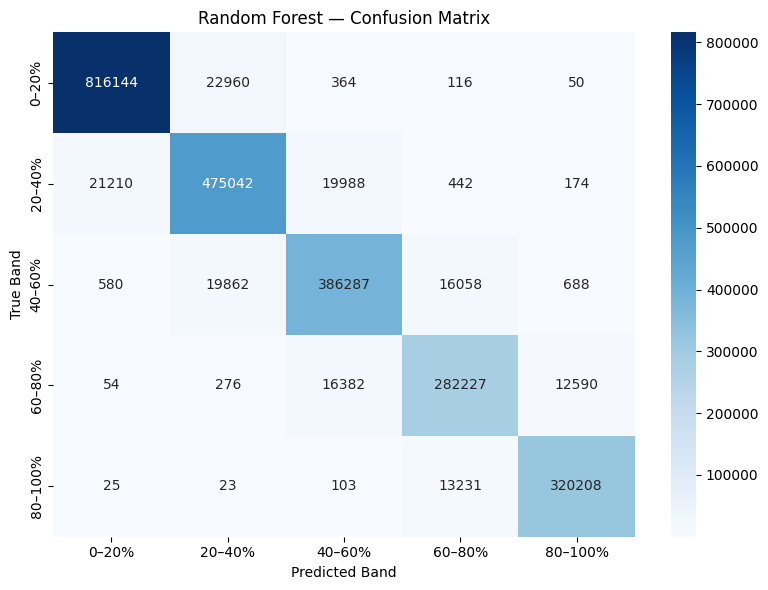

In [22]:
#Confusion matrix for the rf model
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf, labels=rf_model.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=rf_model.classes_,
            yticklabels=rf_model.classes_)
plt.title('Random Forest — Confusion Matrix')
plt.ylabel('True Band')
plt.xlabel('Predicted Band')
plt.tight_layout()
plt.show()


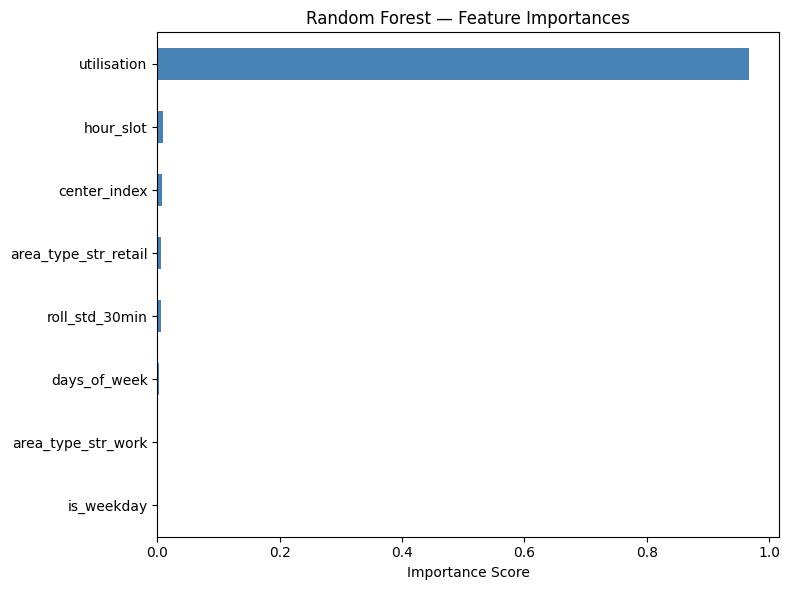

In [23]:
#showing which feature is the most important
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importances.sort_values().plot(kind='barh', figsize=(8, 6), color='steelblue')
plt.title('Random Forest — Feature Importances')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()


So far i have performed random forest classifier on the same train/test split and the results are good especially on the 0-20 and 80-100 bins


# LSTM

In [24]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [25]:
# Selecting features for the model and sorting them 
import numpy as np


SEQ_FEATURES = [
    'utilisation',
    'roll_mean_30min',
    'roll_std_30min',
    'hour_slot',
    'days_of_week',
    'center_index',
]

TARGET_COL = 'util_band_30min'  
# this means the model will look back at the past 6 time stamps and as each data point is 5 min apart so it becomes a 30 minute look back 

TIMESTEPS = 6 

In [26]:
band_to_idx = {b: i for i, b in enumerate(sorted(df[TARGET_COL].unique()))}
idx_to_band = {i: b for b, i in band_to_idx.items()}
df['target_idx'] = df[TARGET_COL].map(band_to_idx)
df_lstm = df.sort_values(['station_id', 'last_reported']).copy()
df_lstm['target_idx'] = df_lstm[TARGET_COL].map(band_to_idx)
#Converted string labels to integers for LSTM model

In [27]:
X_seq = []
y_seq = []

for station_id, group in df_lstm.groupby('station_id', sort=False):
    g = group.reset_index(drop=True)
    feat = g[SEQ_FEATURES].to_numpy()
    tgt  = g['target_idx'].to_numpy()

    # sliding window
    for i in range(len(g) - TIMESTEPS):
        X_seq.append(feat[i:i+TIMESTEPS])
        y_seq.append(tgt[i+TIMESTEPS])   

X_seq = np.array(X_seq, dtype=np.float32)
y_seq = np.array(y_seq, dtype=np.int64)

X_seq.shape, y_seq.shape


((13513078, 6, 6), (13513078,))

In [28]:
#Train test split is 80-20
from sklearn.model_selection import train_test_split

X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_seq, y_seq, test_size=0.2, shuffle=False   
)


In [29]:


num_classes = len(band_to_idx)

model = models.Sequential([
    layers.Input(shape=(TIMESTEPS, len(SEQ_FEATURES))),
    layers.LSTM(64, return_sequences=False),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history = model.fit(
    X_train_seq, y_train_seq,
    validation_split=0.1,
    epochs=5,              # start small; increase if training is stable
    batch_size=512,
    verbose=1,
)


Epoch 1/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 136s 7ms/step - accuracy: 0.8486 - loss: 0.4095 - val_accuracy: 0.8917 - val_loss: 0.2978
Epoch 2/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 128s 7ms/step - accuracy: 0.8572 - loss: 0.3774 - val_accuracy: 0.8971 - val_loss: 0.2855
Epoch 3/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 129s 7ms/step - accuracy: 0.8588 - loss: 0.3717 - val_accuracy: 0.8973 - val_loss: 0.2800
Epoch 4/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 128s 7ms/step - accuracy: 0.8595 - loss: 0.3687 - val_accuracy: 0.8980 - val_loss: 0.2807
Epoch 5/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 136s 7ms/step - accuracy: 0.8600 - loss: 0.3668 - val_accuracy: 0.8971 - val_loss: 0.2789


In [30]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

y_proba_lstm = model.predict(X_test_seq)
y_pred_lstm_idx = np.argmax(y_proba_lstm, axis=1)

# Map back to band labels if you want
y_test_bands = np.array([idx_to_band[i] for i in y_test_seq])
y_pred_bands = np.array([idx_to_band[i] for i in y_pred_lstm_idx])

print("LSTM Accuracy:", accuracy_score(y_test_seq, y_pred_lstm_idx))
print("\nLSTM Classification report:")
print(classification_report(y_test_seq, y_pred_lstm_idx, target_names=[idx_to_band[i] for i in range(num_classes)]))


84457/84457 ━━━━━━━━━━━━━━━━━━━━ 86s 1ms/step
LSTM Accuracy: 0.9086910608092308

LSTM Classification report:
              precision    recall  f1-score   support

       0–20%       0.95      0.96      0.96   1085744
      20–40%       0.87      0.88      0.87    635785
      40–60%       0.87      0.85      0.86    461840
      60–80%       0.87      0.82      0.84    250013
     80–100%       0.94      0.95      0.94    269234

    accuracy                           0.91   2702616
   macro avg       0.90      0.89      0.90   2702616
weighted avg       0.91      0.91      0.91   2702616

